In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

## Business Understanding

### Problem Statement

Perusahaan menghadapi risiko kehilangan pelanggan dan pendapatan ketika pelanggan berhenti berlangganan (*churn*). Perusahaan perlu mengetahui pelanggan mana yang perlu diprioritaskan, karakteristik apa yang berkaitan dengan churn, dan bagaimana merancang program retensi yang lebih terarah.

Analisis ini menggunakan `CLTV`, `churn_score`, kontrak, masa berlangganan, biaya bulanan, dan kepuasan pelanggan. Hasil analisis bersifat **deskriptif**: hubungan yang ditemukan tidak otomatis membuktikan sebab-akibat. Batas anggaran dan strategi retensi juga diperlakukan sebagai simulasi yang perlu diuji dengan data biaya dan hasil program yang sebenarnya.

### Business Question

### 1. Identifikasi & Segmentasi Pelanggan
Berapa banyak pelanggan bernilai tinggi yang memiliki risiko tinggi untuk berhenti berlangganan (*Priority 1: High Value - High Risk*)? Bagaimana status mereka saat ini, baik yang masih berlangganan (*Stayed*) maupun yang sudah berhenti (*Churned*)?

### 2. Mengukur Risiko Kehilangan Pendapatan
Berapa total nilai pelanggan (*CLTV at Risk*) dan total tagihan bulanan (*Monthly Recurring Revenue at Risk*) yang berisiko hilang dari pelanggan Priority 1 yang masih aktif?

### 3. Mencari Penyebab Pelanggan Berisiko Berhenti
- Apakah pelanggan Priority 1 yang berisiko atau sudah berhenti didominasi oleh jenis kontrak tertentu, seperti kontrak bulanan (*Month-to-month*) yang mudah dihentikan?
- Bagaimana hubungan jenis layanan internet (*internet_type*) dan lama berlangganan (*tenure_in_months*) dengan tingkat kepuasan pelanggan (*satisfaction_score*), khususnya pada pelanggan bernilai tinggi?

### 4. Menentukan Strategi Penyelamatan Pelanggan
Berapa batas anggaran yang sesuai untuk mempertahankan pelanggan di setiap kelompok risiko (*tier*)? Strategi apa yang paling sesuai untuk mempertahankan pelanggan Priority 1, seperti menawarkan kontrak tahunan, memberikan potongan tagihan, atau mengganti perangkat yang sudah usang?

### Tujuan Analisis

1. **Memetakan risiko pelanggan**
   - Membagi pelanggan menjadi empat kelompok berdasarkan median `CLTV` dan `churn_score`.
   - Mengidentifikasi pelanggan bernilai tinggi dengan skor risiko relatif tinggi.
2. **Mengukur potensi pendapatan yang terpapar risiko**
   - Menghitung CLTV dan tagihan bulanan pelanggan Priority 1 yang masih aktif.
   - Menjelaskan bahwa nilai tersebut adalah eksposur risiko, bukan kerugian yang pasti terjadi.
3. **Memahami pola churn**
   - Membandingkan churn rate menurut kontrak, metode pembayaran, dan kelompok masa berlangganan.
   - Membandingkan karakteristik pelanggan tanpa menyimpulkan hubungan sebab-akibat.
4. **Menyusun rekomendasi retensi**
   - Mengelompokkan pelanggan sasaran berdasarkan kontrak dan kepuasan.
   - Menyimulasikan batas anggaran berdasarkan asumsi 10% dari CLTV, bukan mengklaimnya sebagai anggaran optimal.

**Batasan:** ambang median merupakan segmentasi relatif pada dataset ini, bukan ambang risiko churn yang tervalidasi secara eksternal.

## Data Preprocessing

### Lingkup Variabel Kolom yang Dibutuhkan

In [ ]:
status_df = pd.read_csv('/content/drive/MyDrive/Bootcamp Assignment/Datdata/Status_Analysis.csv')
payment_df = pd.read_csv('/content/drive/MyDrive/Bootcamp Assignment/Datdata/Payment_Info.csv')
service_df = pd.read_csv('/content/drive/MyDrive/Bootcamp Assignment/Datdata/Service_Options.csv')

In [ ]:
display(status_df.head(3))
display(payment_df.head(3))
display(service_df.head(3))

,customer_id,satisfaction_score,cltv,customer_status,churn_score,churn_label,churn_value,churn_category,churn_reason
0,0002-ORFBO,3,2205,Stayed,65,No,0,Not Applicable,NaN
1,0003-MKNFE,5,5414,Stayed,66,No,0,Not Applicable,NaN
2,0004-TLHLJ,1,4479,Churned,71,Yes,1,Competitor,Competitor had better devices


,customer_id,contract,paperless_billing,payment_method,monthly_ charges,avg_monthly_long_distance_charges,total_charges,total_refunds,total_extra_data_charges,total_long_distance_charges,total_revenue
0,0002-ORFBO,One Year,Yes,Mailed check,65.6,42.39,593.30,0.00,0,381.51,974.81
1,0003-MKNFE,Month-to-Month,No,Mailed check,59.9,10.69,542.40,38.33,10,96.21,610.28
2,0004-TLHLJ,Month-to-Month,Yes,Electronic check,73.9,33.65,280.85,0.00,0,134.60,415.45


,customer_id,tenure,internet_service,phone_service,multiple_lines,avg_monthly_gb_download,unlimited_data,offer,referred_a_friend,number_of_referrals
0,0002-ORFBO,9,Yes,Yes,No,16,Yes,NaN,Yes,2
1,0003-MKNFE,9,Yes,Yes,Yes,10,No,NaN,No,0
2,0004-TLHLJ,4,Yes,Yes,No,30,Yes,Offer E,No,0


In [ ]:
# Tampilkan struktur dataset hasil preprocessing yang digunakan dalam analisis.
status_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   customer_id         7043 non-null   object
 1   satisfaction_score  7043 non-null   int64 
 2   cltv                7043 non-null   int64 
 3   customer_status     7043 non-null   object
 4   churn_score         7043 non-null   int64 
 5   churn_label         7043 non-null   object
 6   churn_value         7043 non-null   int64 
 7   churn_category      7043 non-null   object
 8   churn_reason        1869 non-null   object
dtypes: int64(4), object(5)
memory usage: 495.3+ KB


In [ ]:
payment_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 11 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   customer_id                        7043 non-null   object 
 1   contract                           7043 non-null   object 
 2   paperless_billing                  7043 non-null   object 
 3   payment_method                     7043 non-null   object 
 4   monthly_ charges                   7043 non-null   float64
 5   avg_monthly_long_distance_charges  7043 non-null   float64
 6   total_charges                      7043 non-null   float64
 7   total_refunds                      7043 non-null   float64
 8   total_extra_data_charges           7043 non-null   int64  
 9   total_long_distance_charges        7043 non-null   float64
 10  total_revenue                      7043 non-null   float64
dtypes: float64(6), int64(1), object(4)
memory usage: 605.4+ 

In [ ]:
service_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   customer_id              7043 non-null   object
 1   tenure                   7043 non-null   int64 
 2   internet_service         7043 non-null   object
 3   phone_service            7043 non-null   object
 4   multiple_lines           7043 non-null   object
 5   avg_monthly_gb_download  7043 non-null   int64 
 6   unlimited_data           7043 non-null   object
 7   offer                    3166 non-null   object
 8   referred_a_friend        7043 non-null   object
 9   number_of_referrals      7043 non-null   int64 
dtypes: int64(3), object(7)
memory usage: 550.4+ KB


In [ ]:
# Rapikan nama kolom agar konsisten (contoh: "monthly_ charges" menjadi "monthly_charges")
for _df in [status_df, payment_df, service_df]:
    _df.columns = (_df.columns.str.strip()
                   .str.replace(r"\s+", "", regex=True)
                   .str.replace(r"__+", "_", regex=True))

# Pastikan customer_id tidak kosong dan unik sebelum proses join.
for _name, _df in [('status_df', status_df), ('payment_df', payment_df), ('service_df', service_df)]:
    assert _df['customer_id'].notna().all(), f"customer_id kosong pada {_name}"
    assert _df['customer_id'].is_unique, f"customer_id duplikat pada {_name}"



Pemeriksaan customer_id: seluruh tabel memiliki ID yang tidak kosong dan unik.


In [ ]:
# ambil kolom yg hanya diperlukan

payment_cols = ['customer_id', 'contract', 'monthly_charges', 'payment_method']
service_cols = ['customer_id', 'tenure', 'internet_service', 'offer']

In [ ]:
# Join satu-ke-satu agar jumlah pelanggan tidak bertambah akibat ID duplikat.
merged_df = status_df.merge(
    payment_df[payment_cols], on='customer_id', how='left', validate='one_to_one', indicator='_payment_merge'
)
merged_df = merged_df.merge(
    service_df[service_cols], on='customer_id', how='left', validate='one_to_one', indicator='_service_merge'
)

# Periksa apakah semua customer_id dari tabel utama ditemukan di kedua tabel tambahan.
merge_check = pd.DataFrame({
    'Pemeriksaan': ['Jumlah baris status', 'Jumlah baris setelah join',
                    'ID tidak ditemukan di payment', 'ID tidak ditemukan di service'],
    'Jumlah': [len(status_df), len(merged_df),
               (merged_df['_payment_merge'] != 'both').sum(),
               (merged_df['_service_merge'] != 'both').sum()]
})
display(merge_check)
assert len(merged_df) == len(status_df), 'Jumlah baris berubah setelah join; periksa customer_id.'
merged_df = merged_df.drop(columns=['_payment_merge', '_service_merge'])

,Pemeriksaan,Jumlah
0,Jumlah baris status,7043
1,Jumlah baris setelah join,7043
2,ID tidak ditemukan di payment,0
3,ID tidak ditemukan di service,0


In [ ]:
merged_df.head(2)

,customer_id,satisfaction_score,cltv,customer_status,churn_score,churn_label,churn_value,churn_category,churn_reason,contract,monthly_charges,payment_method,tenure,internet_service,offer
0,0002-ORFBO,3,2205,Stayed,65,No,0,Not Applicable,NaN,One Year,65.6,Mailed check,9,Yes,NaN
1,0003-MKNFE,5,5414,Stayed,66,No,0,Not Applicable,NaN,Month-to-Month,59.9,Mailed check,9,Yes,NaN


In [ ]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         7043 non-null   object 
 1   satisfaction_score  7043 non-null   int64  
 2   cltv                7043 non-null   int64  
 3   customer_status     7043 non-null   object 
 4   churn_score         7043 non-null   int64  
 5   churn_label         7043 non-null   object 
 6   churn_value         7043 non-null   int64  
 7   churn_category      7043 non-null   object 
 8   churn_reason        1869 non-null   object 
 9   contract            7043 non-null   object 
 10  monthly_charges     7043 non-null   float64
 11  payment_method      7043 non-null   object 
 12  tenure              7043 non-null   int64  
 13  internet_service    7043 non-null   object 
 14  offer               3166 non-null   object 
dtypes: float64(1), int64(5), object(9)
memory usage: 825.5+

### Cek Missing Value

In [ ]:
merged_df.isnull().sum()

,0
customer_id,0
satisfaction_score,0
cltv,0
customer_status,0
churn_score,0
churn_label,0
churn_value,0
churn_category,0
churn_reason,5174
contract,0


In [ ]:
# cek missing values

missing_count = merged_df.isnull().sum()
missing_pct = (merged_df.isnull().sum() / len(merged_df) * 100).round(2)
missing_table = pd.DataFrame({
    'Jumlah Missing': missing_count,
    'Persentase (%)': missing_pct
})

missing_table[missing_table['Jumlah Missing'] > 0]

,Jumlah Missing,Persentase (%)
churn_reason,5174,73.46
offer,3877,55.05


In [ ]:
kat_kol_miss = ['churn_reason', 'offer']

for kol in kat_kol_miss:
  value_unik = sorted(merged_df[kol].dropna().unique())
  daftar_ke_bawah = '\n- '.join(value_unik)
  print(f"Kategori pada kolom '{kol}':\n- {daftar_ke_bawah}\n")

Kategori pada kolom 'churn_reason':
- Attitude of service provider
- Attitude of support person
- Competitor had better devices
- Competitor made better offer
- Competitor offered higher download speeds
- Competitor offered more data
- Deceased
- Don't know
- Extra data charges
- Lack of affordable download/upload speed
- Lack of self-service on Website
- Limited range of services
- Long distance charges
- Moved
- Network reliability
- Poor expertise of online support
- Poor expertise of phone support
- Price too high
- Product dissatisfaction
- Service dissatisfaction

Kategori pada kolom 'offer':
- Offer A
- Offer B
- Offer C
- Offer D
- Offer E



### Handling Missing Value

In [ ]:
clean_df = merged_df.copy()
clean_df['churn_reason'] = clean_df['churn_reason'].fillna('Not Applicable')
clean_df['offer'] = clean_df['offer'].fillna('None')

kolom_penting = ['customer_id', 'cltv', 'churn_score', 'customer_status',
                 'contract', 'monthly_charges', 'tenure', 'internet_service', 'satisfaction_score']
missing_penting = clean_df[kolom_penting].isna().sum()
display(missing_penting[missing_penting > 0].rename('Jumlah Missing').to_frame())
if missing_penting.sum() > 0:
    print('Perhatian: tangani missing value pada kolom penting sebelum melanjutkan analisis.')

,Jumlah Missing


In [ ]:
clean_df.isnull().sum()

,0
customer_id,0
satisfaction_score,0
cltv,0
customer_status,0
churn_score,0
churn_label,0
churn_value,0
churn_category,0
churn_reason,0
contract,0


In [ ]:
clean_df['churn_reason'].value_counts().head(5)

,count
churn_reason,
Not Applicable,5174
Competitor had better devices,313
Competitor made better offer,311
Attitude of support person,220
Don't know,130


In [ ]:
clean_df['offer'].value_counts()

,count
offer,
None,3877
Offer B,824
Offer E,805
Offer D,602
Offer A,520
Offer C,415


In [ ]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         7043 non-null   object 
 1   satisfaction_score  7043 non-null   int64  
 2   cltv                7043 non-null   int64  
 3   customer_status     7043 non-null   object 
 4   churn_score         7043 non-null   int64  
 5   churn_label         7043 non-null   object 
 6   churn_value         7043 non-null   int64  
 7   churn_category      7043 non-null   object 
 8   churn_reason        7043 non-null   object 
 9   contract            7043 non-null   object 
 10  monthly_charges     7043 non-null   float64
 11  payment_method      7043 non-null   object 
 12  tenure              7043 non-null   int64  
 13  internet_service    7043 non-null   object 
 14  offer               7043 non-null   object 
dtypes: float64(1), int64(5), object(9)
memory usage: 825.5+

### Cek baris duplikat

In [ ]:
# cek duplikat

duplicate_rows = clean_df.duplicated().sum()
duplicate_pct = round((duplicate_rows / len(clean_df)) * 100, 2)

print(f"\nJumlah Baris Duplikat: {duplicate_rows} baris ({duplicate_pct}%)")


Jumlah Baris Duplikat: 0 baris (0.0%)


Tidak terdapat bars duplikat

### Standardisasi Variable dan Value

In [ ]:
# cek kolom standardisasi

kategori_cols = clean_df.select_dtypes(include=['object']).columns.drop('customer_id')

for col in kategori_cols:
    unik = clean_df[col].unique()
    print(f"\nKolom: '{col}' ({len(unik)} nilai unik)")
    for val in sorted(unik):
        count = (clean_df[col] == val).sum()
        print(f"  - {val} ({count:,} data)")


Kolom: 'customer_status' (3 nilai unik)
  - Churned (1,869 data)
  - Joined (454 data)
  - Stayed (4,720 data)

Kolom: 'churn_label' (2 nilai unik)
  - No (5,174 data)
  - Yes (1,869 data)

Kolom: 'churn_category' (6 nilai unik)
  - Attitude (314 data)
  - Competitor (841 data)
  - Dissatisfaction (303 data)
  - Not Applicable (5,174 data)
  - Other (200 data)
  - Price (211 data)

Kolom: 'churn_reason' (21 nilai unik)
  - Attitude of service provider (94 data)
  - Attitude of support person (220 data)
  - Competitor had better devices (313 data)
  - Competitor made better offer (311 data)
  - Competitor offered higher download speeds (100 data)
  - Competitor offered more data (117 data)
  - Deceased (6 data)
  - Don't know (130 data)
  - Extra data charges (39 data)
  - Lack of affordable download/upload speed (30 data)
  - Lack of self-service on Website (29 data)
  - Limited range of services (37 data)
  - Long distance charges (64 data)
  - Moved (46 data)
  - Network reliability

In [ ]:
# Validasi konsistensi dua indikator churn.
label_map = {'Yes': 1, 'No': 0}
label_as_value = clean_df['churn_label'].map(label_map)
consistency_check = pd.DataFrame({
    'Pemeriksaan': ['Label yang tidak dikenali', 'Baris churn_label berbeda dari churn_value'],
    'Jumlah': [clean_df['churn_label'].map(label_map).isna().sum(),
               (label_as_value != clean_df['churn_value']).sum()]
})
display(consistency_check)
assert clean_df['churn_label'].map(label_map).notna().all(), 'Ada kategori churn_label yang belum dipetakan.'
assert (label_as_value == clean_df['churn_value']).all(), 'churn_label dan churn_value tidak konsisten.'

,Pemeriksaan,Jumlah
0,Label yang tidak dikenali,0
1,Baris churn_label berbeda dari churn_value,0


### Transformasi Tipe Data

In [ ]:
# Ubah kolom kategorikal menjadi dtype category agar lebih efisien.
kolom_kategori = [
    'customer_status', 'churn_label', 'churn_category', 'contract',
    'payment_method', 'internet_service', 'offer'
]
clean_df[kolom_kategori] = clean_df[kolom_kategori].astype('category')
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   customer_id         7043 non-null   object  
 1   satisfaction_score  7043 non-null   int64   
 2   cltv                7043 non-null   int64   
 3   customer_status     7043 non-null   category
 4   churn_score         7043 non-null   int64   
 5   churn_label         7043 non-null   category
 6   churn_value         7043 non-null   int64   
 7   churn_category      7043 non-null   category
 8   churn_reason        7043 non-null   object  
 9   contract            7043 non-null   category
 10  monthly_charges     7043 non-null   float64 
 11  payment_method      7043 non-null   category
 12  tenure              7043 non-null   int64   
 13  internet_service    7043 non-null   category
 14  offer               7043 non-null   category
dtypes: category(7), float64(1), int64(5), 

### Cek Outliers

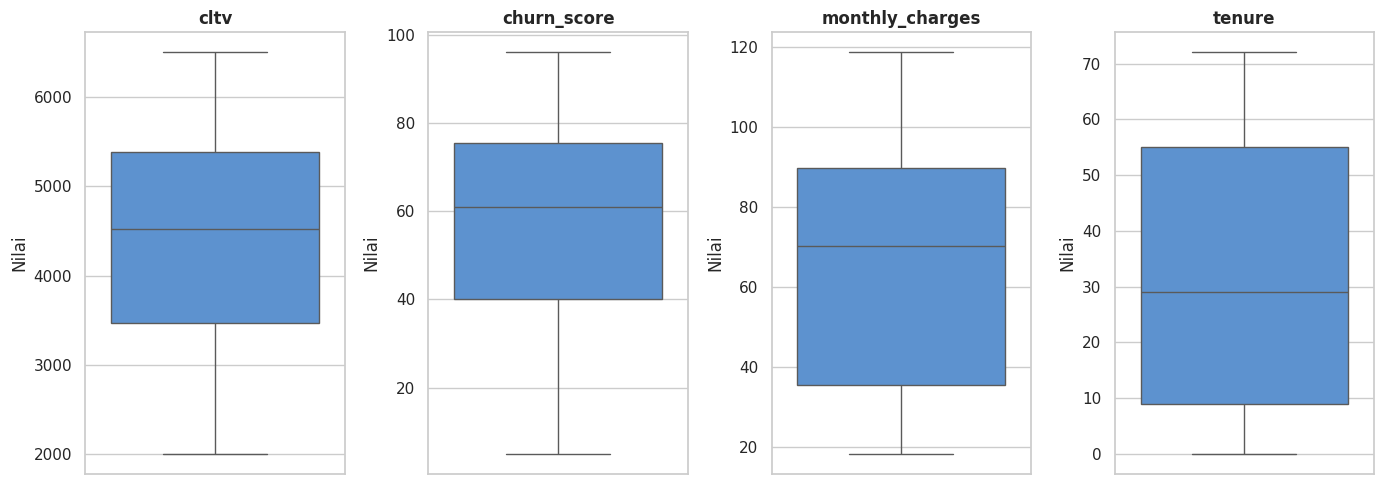

In [ ]:
# cek outliers

num_cols = ['cltv', 'churn_score', 'monthly_charges', 'tenure']

plt.figure(figsize=(14, 5))
sns.set_theme(style="whitegrid")

for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 4, i)
    sns.boxplot(y=clean_df[col], color='#4a90e2', flierprops={'marker': 'o', 'markersize': 5, 'markerfacecolor': 'red'})
    plt.title(f'{col}', fontsize=12, fontweight='bold')
    plt.ylabel('Nilai')

plt.tight_layout()
plt.show()

In [ ]:
# cek outlier dengan metode iqr

num_cols = ['cltv', 'churn_score', 'monthly_charges', 'tenure']

outlier_summary = []

for col in num_cols:
    q1 = clean_df[col].quantile(0.25)
    q3 = clean_df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = clean_df[(clean_df[col] < lower_bound) | (clean_df[col] > upper_bound)]
    jumlah_outlier = len(outliers)
    persentase_outlier = (jumlah_outlier / len(clean_df)) * 100

    outlier_summary.append({
        'Kolom': col,
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Batas Bawah': round(lower_bound, 2),
        'Batas Atas': round(upper_bound, 2),
        'Jumlah Outlier': jumlah_outlier,
        'Persentase (%)': f"{persentase_outlier:.2f}%"
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,Kolom,Q1 (25%),Q3 (75%),IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,cltv,3469.0,5380.50,1911.50,601.75,8247.75,0,0.00%
1,churn_score,40.0,75.50,35.50,-13.25,128.75,0,0.00%
2,monthly_charges,35.5,89.85,54.35,-46.02,171.38,0,0.00%
3,tenure,9.0,55.00,46.00,-60.00,124.00,0,0.00%


Pada dataset pelanggan, nilai CLTV atau biaya yang tinggi bisa merupakan nilai bisnis yang valid. Data numerik memiliki sebaran yang baik dan masih dalam batas wajar. Karena tidak ditemukan nilai yang terlalu ekstrem atau kesalahan input, data tidak perlu dihilangkan.

## Feature Engineering

In [ ]:
# Segmentasi relatif berdasarkan median CLTV dan churn_score.
# Median digunakan untuk membentuk kuadran pada dataset ini
cltv_med = clean_df['cltv'].median()
churn_med = clean_df['churn_score'].median()

conditions = [
    (clean_df['cltv'] >= cltv_med) & (clean_df['churn_score'] >= churn_med),
    (clean_df['cltv'] >= cltv_med) & (clean_df['churn_score'] < churn_med),
    (clean_df['cltv'] < cltv_med) & (clean_df['churn_score'] >= churn_med),
]
choices = [
    'Priority 1 (High Value - High Risk)',
    'Priority 2 (High Value - Low Risk)',
    'Priority 3 (Low Value - High Risk)',
]
clean_df['customer_tier'] = np.select(conditions, choices, default='Priority 4 (Low Value - Low Risk)')

print(f'Median CLTV: ${cltv_med:,.2f}')
print(f'Median churn_score: {churn_med:,.2f}')
display(clean_df['customer_tier'].value_counts().rename_axis('customer_tier').to_frame('jumlah_pelanggan'))

Median CLTV: $4,527.00
Median churn_score: 61.00


,jumlah_pelanggan
customer_tier,
Priority 3 (Low Value - High Risk),1900
Priority 2 (High Value - Low Risk),1855
Priority 1 (High Value - High Risk),1667
Priority 4 (Low Value - Low Risk),1621


Pelanggan dibagi menjadi empat kelompok berdasarkan median `cltv` (nilai pelanggan) dan `churn_score` (skor risiko pelanggan berhenti berlangganan).

- **Priority 1 (High Value - High Risk):** Nilai pelanggan tinggi, tetapi berisiko tinggi untuk berhenti.
- **Priority 2 (High Value - Low Risk):** Nilai pelanggan tinggi dan berisiko lebih rendah untuk berhenti.
- **Priority 3 (Low Value - High Risk):** Nilai pelanggan lebih rendah, tetapi berisiko tinggi untuk berhenti.
- **Priority 4 (Low Value - Low Risk):** Nilai pelanggan lebih rendah dan berisiko lebih rendah untuk berhenti.

Median digunakan sebagai batas untuk membedakan nilai dan risiko pelanggan dalam dataset ini.

Untuk kolomo `cltv` dan `churn_score` sudah tersedia dalam dataset, sehingga tidak perlu dihitung ulang.

- **CLTV (Customer Lifetime Value):** Perkiraan nilai pelanggan bagi perusahaan selama hubungan berlangganan.
- **Churn Score:** Skor yang menunjukkan tingkat risiko pelanggan berhenti berlangganan. Semakin tinggi skornya, semakin tinggi risiko churn menurut model penilaian pada dataset.

Kedua kolom ini digunakan untuk mengelompokkan pelanggan berdasarkan nilai dan risiko churn, dengan median masing2 kolom sebagai batas pembanding.

In [ ]:
# Proyeksi tagihan 12 bulan jik tarif bulanan saat ini tetap
# Ini bukan pendapatan tahunan aktual dan tidak memperhitungkan churn/perubahan tarif
clean_df['projected_annual_charges'] = clean_df['monthly_charges'] * 12

# Asumsi simulasi: plafon biaya retensi maksimum 10% dari CLTV.
# Angka ini bukan anggaran optimal yang telah tervalidasi.
RETENTION_BUDGET_RATE = 0.10
clean_df['retention_budget_cap'] = (clean_df['cltv'] * RETENTION_BUDGET_RATE).round(2)

In [ ]:
# Pengelompokan Lamanya Siklus Hidup Pelanggan (tenure_group)
def categorize_tenure(months):
    if months <= 12:
        return '01. <= 1 Tahun (Baru)'
    elif months <= 24:
        return '02. 1 - 2 Tahun (Menengah)'
    elif months <= 48:
        return '03. 2 - 4 Tahun (Mapan)'
    else:
        return '04. > 4 Tahun (Loyal)'

clean_df['tenure_group'] = clean_df['tenure'].apply(categorize_tenure)

In [ ]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   customer_id               7043 non-null   object  
 1   satisfaction_score        7043 non-null   int64   
 2   cltv                      7043 non-null   int64   
 3   customer_status           7043 non-null   category
 4   churn_score               7043 non-null   int64   
 5   churn_label               7043 non-null   category
 6   churn_value               7043 non-null   int64   
 7   churn_category            7043 non-null   category
 8   churn_reason              7043 non-null   object  
 9   contract                  7043 non-null   category
 10  monthly_charges           7043 non-null   float64 
 11  payment_method            7043 non-null   category
 12  tenure                    7043 non-null   int64   
 13  internet_service          7043 non-null   catego

In [ ]:
# Tampilkan struktur dataset hasil preprocessing yang digunakan dalam analisis.
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   customer_id               7043 non-null   object  
 1   satisfaction_score        7043 non-null   int64   
 2   cltv                      7043 non-null   int64   
 3   customer_status           7043 non-null   category
 4   churn_score               7043 non-null   int64   
 5   churn_label               7043 non-null   category
 6   churn_value               7043 non-null   int64   
 7   churn_category            7043 non-null   category
 8   churn_reason              7043 non-null   object  
 9   contract                  7043 non-null   category
 10  monthly_charges           7043 non-null   float64 
 11  payment_method            7043 non-null   category
 12  tenure                    7043 non-null   int64   
 13  internet_service          7043 non-null   catego

In [ ]:
# Export download ke PC

from google.colab import files

clean_df.to_csv('new_status_analysis2.csv', index=False)
files.download('new_status_analysis2.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Exploratory Data Analysis (EDA)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")
palette_custom = ["#ff9999", "#66b3ff", "#99ff99", "#ffcc99"]

### Analisis Deskriptif

In [ ]:
num_cols = ['satisfaction_score', 'cltv', 'churn_score', 'monthly_charges', 'tenure', 'projected_annual_charges', 'retention_budget_cap']

# Menghitung metrik statistik numeikal
desc_num = clean_df[num_cols].describe().T
desc_num['median'] = clean_df[num_cols].median()
desc_num['iqr'] = desc_num['75%'] - desc_num['25%']

desc_num = desc_num[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'iqr', 'max']]
display(desc_num)

,count,mean,median,std,min,25%,75%,iqr,max
satisfaction_score,7043.0,3.244924,3.00,1.201657,1.00,3.0,4.00,1.00,5.00
cltv,7043.0,4400.295755,4527.00,1183.057152,2003.00,3469.0,5380.50,1911.50,6500.00
churn_score,7043.0,58.505040,61.00,21.170031,5.00,40.0,75.50,35.50,96.00
monthly_charges,7043.0,64.761692,70.35,30.090047,18.25,35.5,89.85,54.35,118.75
tenure,7043.0,32.371149,29.00,24.559481,0.00,9.0,55.00,46.00,72.00
projected_annual_charges,7043.0,777.140310,844.20,361.080565,219.00,426.0,1078.20,652.20,1425.00
retention_budget_cap,7043.0,440.029575,452.70,118.305715,200.30,346.9,538.05,191.15,650.00


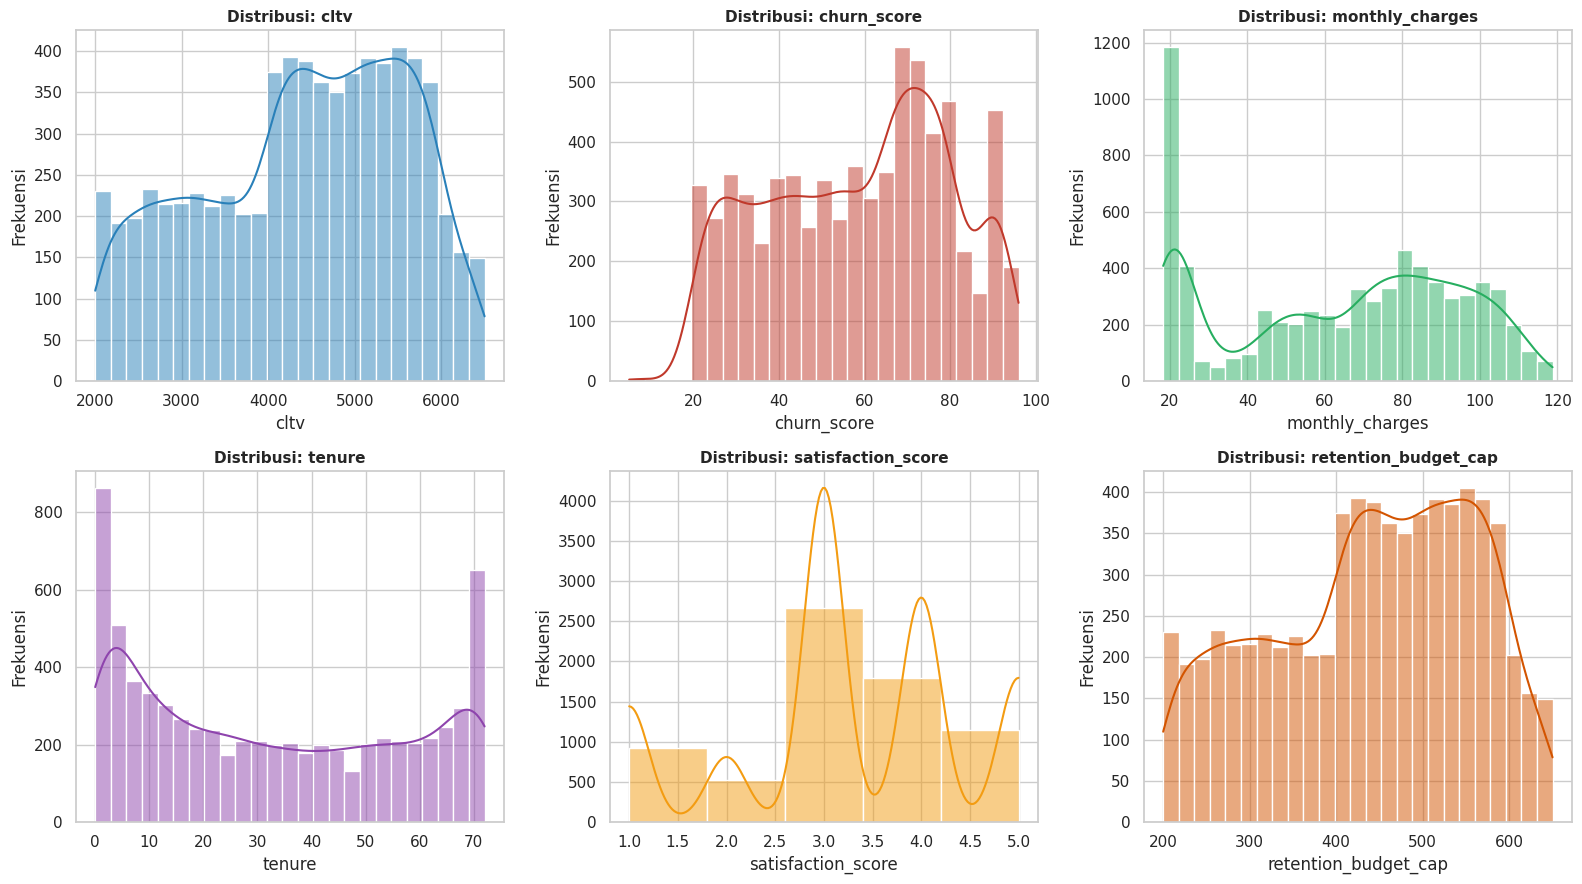

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
features_plot = ['cltv', 'churn_score', 'monthly_charges', 'tenure', 'satisfaction_score', 'retention_budget_cap']
colors = ['#2980b9', '#c0392b', '#27ae60', '#8e44ad', '#f39c12', '#d35400']

for i, col in enumerate(features_plot):
    ax = axes[i//3, i%3]
    sns.histplot(clean_df[col], kde=True, ax=ax, color=colors[i], bins=25 if col != 'satisfaction_score' else 5)
    ax.set_title(f'Distribusi: {col}', fontsize=11, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

Interpretasi Distribusi Data Pelanggan

- **CLTV (Customer Lifetime Value):** Banyak pelanggan memiliki nilai di atas 4.000, menunjukkan potensi nilai finansial pelanggan yang cukup besar bagi perusahaan.
- **Churn Score:** Banyak pelanggan memiliki skor 60–90, yang menunjukkan tingkat risiko berhenti berlangganan yang relatif tinggi menurut skor pada dataset.
- **Monthly Charges:** Pelanggan banyak menggunakan paket dengan biaya sekitar 20, sementara kelompok lainnya membayar sekitar 70–110 per bulan.
- **Tenure (Lama Berlangganan):** Pelanggan banyak terkumpul pada dua kelompok, yaitu pelanggan baru (kurang dari 5 bulan) dan pelanggan yang sudah lama berlangganan (sekitar 70 bulan).
- **Satisfaction Score:** Sebagian besar pelanggan memberikan skor 3 atau netral. Kondisi ini perlu diperhatikan karena kepuasan mereka belum tinggi dan perlu ditelusuri lebih lanjut.
- **Retention Budget Cap:** Polanya mirip dengan CLTV, sbagian besar estimasi batas anggaran retensi berada di kisaran 450–600 per pelanggan.

In [ ]:
cat_cols = ['customer_status', 'contract', 'internet_service', 'payment_method', 'offer', 'customer_tier', 'tenure_group']

print("\n" + "="*50)
print("=== Distirbusi frekuensi kategorikal ===")
for col in cat_cols:
    summary_cat = pd.DataFrame({
        'Jumlah Pelanggan': clean_df[col].value_counts(),
        'Persentase (%)': (clean_df[col].value_counts(normalize=True) * 100).round(2)
    })
    print(f"\n--- Analisis Kolom: {col} ---")
    display(summary_cat)


=== Distirbusi frekuensi kategorikal ===

--- Analisis Kolom: customer_status ---


,Jumlah Pelanggan,Persentase (%)
customer_status,,
Stayed,4720,67.02
Churned,1869,26.54
Joined,454,6.45



--- Analisis Kolom: contract ---


,Jumlah Pelanggan,Persentase (%)
contract,,
Month-to-Month,3610,51.26
Two Year,1883,26.74
One Year,1550,22.01



--- Analisis Kolom: internet_service ---


...

,Jumlah Pelanggan,Persentase (%)
offer,,
None,3877,55.05
Offer B,824,11.70
Offer E,805,11.43
Offer D,602,8.55
Offer A,520,7.38
Offer C,415,5.89



--- Analisis Kolom: customer_tier ---


,Jumlah Pelanggan,Persentase (%)
customer_tier,,
Priority 3 (Low Value - High Risk),1900,26.98
Priority 2 (High Value - Low Risk),1855,26.34
Priority 1 (High Value - High Risk),1667,23.67
Priority 4 (Low Value - Low Risk),1621,23.02



--- Analisis Kolom: tenure_group ---


,Jumlah Pelanggan,Persentase (%)
tenure_group,,
04. > 4 Tahun (Loyal),2239,31.79
01. <= 1 Tahun (Baru),2186,31.04
03. 2 - 4 Tahun (Mapan),1594,22.63
02. 1 - 2 Tahun (Menengah),1024,14.54


/tmp/ipykernel_1547/3680192545.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clean_df, x='customer_status', ax=ax1, palette=['#3498db', '#e74c3c', '#2ecc71'])
/tmp/ipykernel_1547/3680192545.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clean_df, x='contract', ax=ax2, palette='Blues_r')
/tmp/ipykernel_1547/3680192545.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clean_df, x='customer_tier', order=tier_order, ax=ax3, palette='Reds_r')
/tmp/ipykernel_1547/3680192545.py:42: UserWarning: set_ticklabels() s

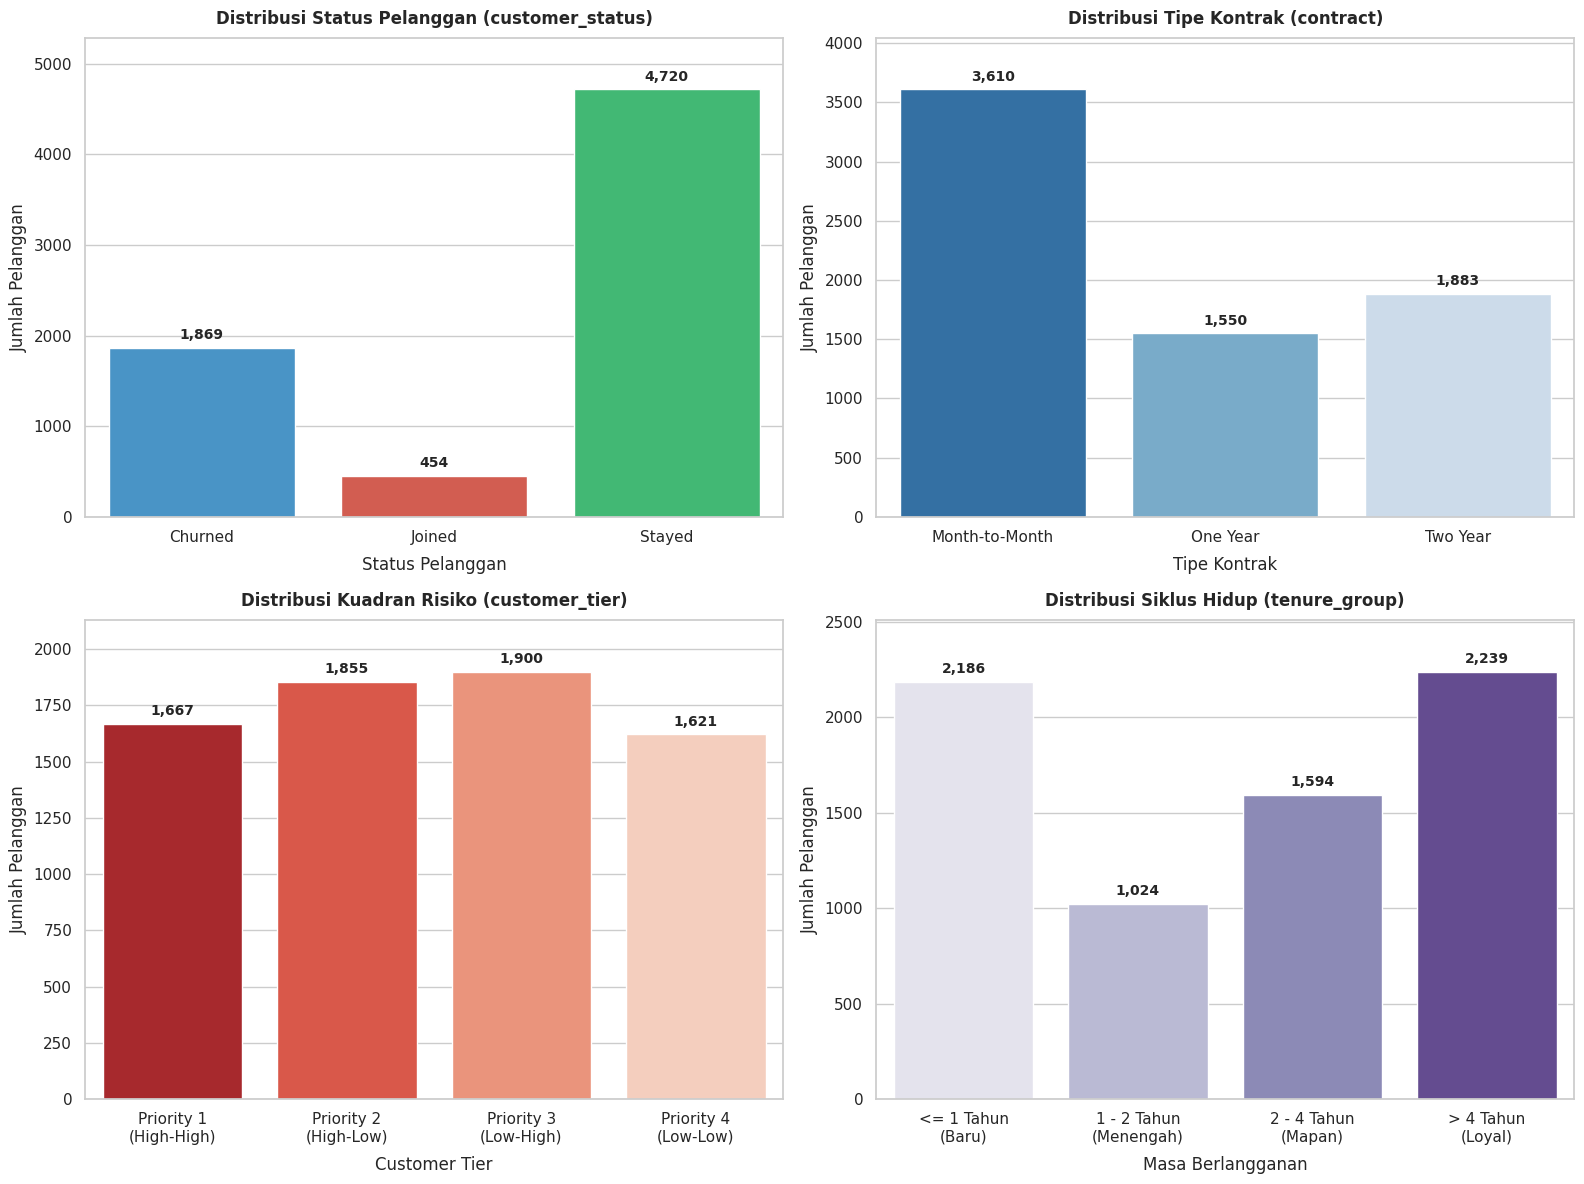

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sns.set_theme(style="whitegrid")

# Visualisasi barchart
# 1. Distribusi Status Pelanggan
ax1 = axes[0, 0]
sns.countplot(data=clean_df, x='customer_status', ax=ax1, palette=['#3498db', '#e74c3c', '#2ecc71'])
ax1.set_title('Distribusi Status Pelanggan (customer_status)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Status Pelanggan', labelpad=8)
ax1.set_ylabel('Jumlah Pelanggan')
for p in ax1.patches:
    h = p.get_height()
    ax1.annotate(f"{int(h):,}", (p.get_x() + p.get_width() / 2., h),
                 ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4), textcoords='offset points')
ax1.set_ylim(0, clean_df['customer_status'].value_counts().max() * 1.12)

# 2. Distribusi Tipe Kontrak
ax2 = axes[0, 1]
sns.countplot(data=clean_df, x='contract', ax=ax2, palette='Blues_r')
ax2.set_title('Distribusi Tipe Kontrak (contract)', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Tipe Kontrak', labelpad=8)
ax2.set_ylabel('Jumlah Pelanggan')
for p in ax2.patches:
    h = p.get_height()
    ax2.annotate(f"{int(h):,}", (p.get_x() + p.get_width() / 2., h),
                 ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4), textcoords='offset points')
ax2.set_ylim(0, clean_df['contract'].value_counts().max() * 1.12)

# 3. Distribusi Kuadran Risiko (Customer Tier) - Dibuat Tegak Lurus
ax3 = axes[1, 0]
tier_order = [
    'Priority 1 (High Value - High Risk)',
    'Priority 2 (High Value - Low Risk)',
    'Priority 3 (Low Value - High Risk)',
    'Priority 4 (Low Value - Low Risk)'
]
sns.countplot(data=clean_df, x='customer_tier', order=tier_order, ax=ax3, palette='Reds_r')
ax3.set_title('Distribusi Kuadran Risiko (customer_tier)', fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel('Customer Tier', labelpad=8)
ax3.set_ylabel('Jumlah Pelanggan')
# Singkat label sumbu X agar rapi dan tidak tumpang tindih
ax3.set_xticklabels(['Priority 1\n(High-High)', 'Priority 2\n(High-Low)', 'Priority 3\n(Low-High)', 'Priority 4\n(Low-Low)'])
for p in ax3.patches:
    h = p.get_height()
    ax3.annotate(f"{int(h):,}", (p.get_x() + p.get_width() / 2., h),
                 ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4), textcoords='offset points')
ax3.set_ylim(0, clean_df['customer_tier'].value_counts().max() * 1.12)

# 4. Distribusi Siklus Hidup (Tenure Group) - Terurut Rapi
ax4 = axes[1, 1]
tenure_order = [
    '01. <= 1 Tahun (Baru)',
    '02. 1 - 2 Tahun (Menengah)',
    '03. 2 - 4 Tahun (Mapan)',
    '04. > 4 Tahun (Loyal)'
]
sns.countplot(data=clean_df, x='tenure_group', order=tenure_order, ax=ax4, palette='Purples')
ax4.set_title('Distribusi Siklus Hidup (tenure_group)', fontsize=12, fontweight='bold', pad=10)
ax4.set_xlabel('Masa Berlangganan', labelpad=8)
ax4.set_ylabel('Jumlah Pelanggan')
ax4.set_xticklabels(['<= 1 Tahun\n(Baru)', '1 - 2 Tahun\n(Menengah)', '2 - 4 Tahun\n(Mapan)', '> 4 Tahun\n(Loyal)'])
for p in ax4.patches:
    h = p.get_height()
    ax4.annotate(f"{int(h):,}", (p.get_x() + p.get_width() / 2., h),
                 ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4), textcoords='offset points')
ax4.set_ylim(0, clean_df['tenure_group'].value_counts().max() * 1.12)

plt.tight_layout()
plt.show()

Interpretasi Distribusi Pelanggan

1. **Status Pelanggan (`customer_status`):** Mayoritas pelanggan masih aktif (*Stayed*) sebanyak 4.720. Namun, pelanggan yang berhenti (*Churned*) mencapai 1.869, jauh lebih banyak daripada pelanggan baru (*Joined*) sebanyak 454.

2. **Tipe Kontrak (`contract`):** Kontrak bulanan (*Month-to-Month*) mendominasi dengan 3.610 pelanggan. Banyaknya pelanggan dengan kontrak jangka pendek menjadi perhatian karena mereka lebih mudah mengakhiri langganan dibandingkan pelanggan dengan kontrak jangka panjang.

3. **Kelompok Risiko (`customer_tier`):** Jumlah pelanggan di keempat kelompok risiko relatif merata, berkisar antara 1.621–1.900 pelanggan. Sebanyak **1.667 pelanggan Priority 1** memiliki nilai tinggi dan risiko churn tinggi, sehingga perlu menjadi prioritas strategi retensi.

4. **Lama Berlangganan (`tenure_group`):** Pelanggan banyak terkumpul pada dua kelompok, yaitu yang berlangganan selama 1 tahun atau kurang (2.186 pelanggan) dan yang sudah berlangganan lebih dari 4 tahun (2.239 pelanggan). Perusahaan perlu memperkuat upaya retensi pelanggan baru agar mereka tetap berlangganan setelah tahun pertama.

### Analisis Hubungan Antar-variabel

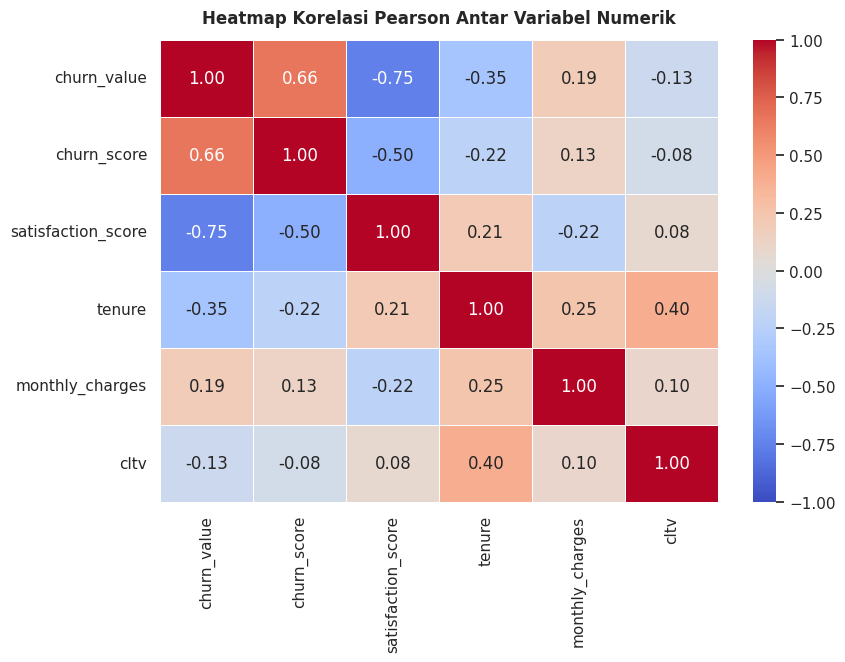

In [ ]:
# heatmap korelasi antar variabel numerik

num_vars = ['churn_value', 'churn_score', 'satisfaction_score', 'tenure', 'monthly_charges', 'cltv']
corr_matrix = clean_df[num_vars].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap Korelasi Pearson Antar Variabel Numerik', fontsize=12, fontweight='bold', pad=12)
plt.show()

Interpretasi Korelasi Antarvariabel

1. **Kepuasan Pelanggan:** `satisfaction_score` memiliki korelasi negatif kuat dengan `churn_value` (-0.75). Skor kepuasan yang lebih rendah berkaitan dengan risiko churn yang lebih tinggi.

2. **Churn Score:** Memiliki korelasi positif kuat dengan `churn_value` (0.66), menunjukkan bahwa skor risiko sejalan dengan status churn dalam data.

3. **Tagihan Bulanan:** `monthly_charges` memiliki korelasi lemah dengan `churn_value` (0.19), sehingga tagihan bulanan saja belum cukup menjelaskan pola churn.

4. **Lama Berlangganan:** `tenure` berkorelasi positif dengan `cltv` (0.40) dan negatif dengan `churn_value` (-0.35). Pelanggan yang lebih lama berlangganan cenderung memiliki CLTV lebih tinggi dan lebih jarang churn.

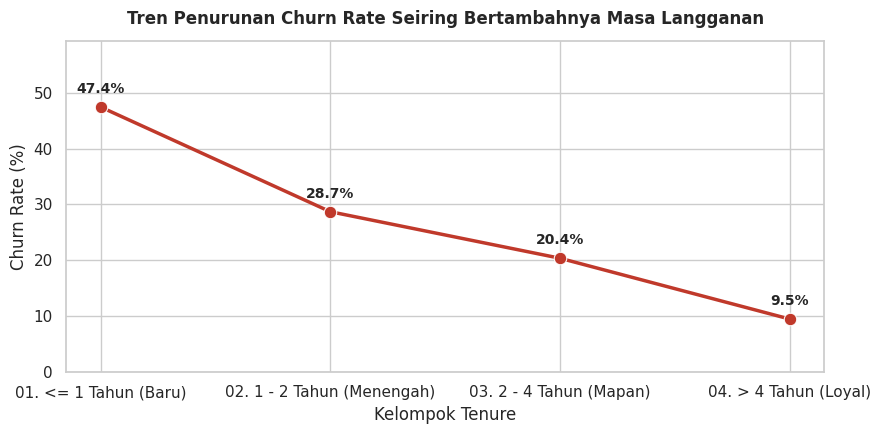

In [ ]:
# analisisis tren siklus hidup - churn rate per kelompok tenure

tenure_trend = clean_df.groupby('tenure_group', observed=False)['churn_value'].mean().reset_index()
tenure_trend['churn_rate'] = tenure_trend['churn_value'] * 100

plt.figure(figsize=(9, 4.5))
ax_trend = sns.lineplot(data=tenure_trend, x='tenure_group', y='churn_rate', marker='o', markersize=9, color='#c0392b', linewidth=2.5)
plt.title('Tren Penurunan Churn Rate Seiring Bertambahnya Masa Langganan', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Kelompok Tenure')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, max(tenure_trend['churn_rate']) * 1.25)

for x, y in zip(range(len(tenure_trend)), tenure_trend['churn_rate']):
    plt.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 10), ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

Interpretasi Churn Rate Berdasarkan Masa Langganan

- **Tahun Pertama Paling Kritis:** Pelanggan dengan masa langganan ≤ 1 tahun memiliki churn rate tertinggi, yaitu **47,4%**.
- **Risiko Menurun Seiring Waktu:** Churn rate turun menjadi **28,7%** pada masa langganan 1–2 tahun dan **20,4%** pada 2–4 tahun.
- **Pelanggan Lama Lebih Loyal:** Pelanggan yang berlangganan lebih dari 4 tahun memiliki churn rate terendah, yaitu **9,5%**.

> Bisa dengan memfokuskan strategi retensi pada 12 bulan pertama melalui proses onboarding yang baik dan penanganan keluhan yang cepat agar pelanggan tetap bertahan.

### Menjawab Pertanyaan Bisnis

#### Q1 Identifikasi & Segmentasi Pelanggan
Berapa banyak pelanggan bernilai tinggi yang memiliki risiko tinggi untuk berhenti berlangganan (Priority 1: High Value - High Risk)? Bagaimana status mereka saat ini, baik yang masih berlangganan (Stayed) maupun yang sudah berhenti (Churned)?

In [ ]:
p1_data = clean_df[clean_df['customer_tier'] == 'Priority 1 (High Value - High Risk)']

# Hitung jumlah riil dan persentase statusnya
q1_result = pd.DataFrame({
    'Jumlah Pelanggan': p1_data['customer_status'].value_counts(),
    'Persentase (%)': (p1_data['customer_status'].value_counts(normalize=True) * 100).round(2)
})

# Tambahkan baris total
q1_result.loc['Total Priority 1'] = [len(p1_data), 100.0]

display(q1_result)

,Jumlah Pelanggan,Persentase (%)
customer_status,,
Stayed,839.0,50.33
Churned,790.0,47.39
Joined,38.0,2.28
Total Priority 1,1667.0,100.00


Interpretasi Q1: Identifikasi & Status Pelanggan Priority 1

Terdapat **1.667 pelanggan Priority 1 (High Value – High Risk)**, dengan rincian:

- **Stayed: 839 pelanggan (50,33%)** — Masih aktif dan menjadi target utama program retensi untuk mencegah kehilangan pendapatan.
- **Churned: 790 pelanggan (47,39%)** — Sudah berhenti berlangganan, menunjukkan tingginya risiko kehilangan pelanggan bernilai tinggi.
- **Joined: 38 pelanggan (2,28%)** — Pelanggan baru yang perlu mendapat pendampingan sejak awal agar tetap berlangganan.

> Program retensi perlu memprioritaskan **839 pelanggan aktif** untuk mengurangi risiko kehilangan pelanggan dan pendapatan.

#### Q2 Mengukur Risiko Kehilangan Pendapatan
Berapa total nilai pelanggan (CLTV at Risk) dan total tagihan bulanan (Monthly Recurring Revenue at Risk) yang berisiko hilang dari pelanggan Priority 1 yang masih aktif?

In [ ]:
# Filter khusus pelanggan Priority 1 yang masih aktif (Stayed)
p1_aktif = clean_df[(clean_df['customer_tier'] == 'Priority 1 (High Value - High Risk)') &
                    (clean_df['customer_status'] == 'Stayed')]

# itung total nilai risiko sesuai pertanyaan bisnis
total_akun = len(p1_aktif)
total_cltv_risk = p1_aktif['cltv'].sum()
total_mrr_risk = p1_aktif['monthly_charges'].sum()

# tabel ringkasan Q2
q2_result = pd.DataFrame({
    'Pertanyaan Bisnis': [
        'Total Nilai Pelanggan (CLTV at Risk)',
        'Total Tagihan Bulanan (MRR at Risk)'
    ],
    'Total Nominal Berisiko': [
        f"${total_cltv_risk:,.2f}",
        f"${total_mrr_risk:,.2f}"
    ],
    'Rata-rata per Akun': [
        f"${total_cltv_risk / total_akun:,.2f}",
        f"${total_mrr_risk / total_akun:,.2f}"
    ]
})

print(f"=== (Target: {total_akun:,} Akun Priority 1 Aktif) ===")
display(q2_result)

=== (Target: 839 Akun Priority 1 Aktif) ===


,Pertanyaan Bisnis,Total Nominal Berisiko,Rata-rata per Akun
0,Total Nilai Pelanggan (CLTV at Risk),"$4,567,572.00","$5,444.07"
1,Total Tagihan Bulanan (MRR at Risk),"$55,498.65",$66.15


Interpretasi Q2: Eksposur Pendapatan pada Pelanggan Priority 1 Aktif

Dari **839 pelanggan Priority 1 yang masih aktif**, nilai yang terpapar risiko adalah:

- **CLTV at Risk: \$4.567.572,00**, atau rata-rata sekitar **$5.444,07 per pelanggan**.
- **MRR at Risk: \$55.498,65 per bulan**, atau rata-rata sekitar **\$66,15 per pelanggan per bulan**.

Angka tersebut menggambarkan nilai pelanggan dan tagihan bulanan yang terkait dengan kelompok berisiko. Angka itu **bukan kerugian yang pasti terjadi**, karena tidak semua pelanggan akan churn dan CLTV bukan berarti pendapatan yang pasti diterima perusahaan.

#### Q3 Mencari Penyebab Pelanggan Berisiko Berhenti
- Apakah pelanggan Priority 1 yang berisiko atau sudah berhenti didominasi oleh jenis kontrak tertentu, seperti kontrak bulanan (Month-to-month) yang mudah dihentikan?
- Bagaimana hubungan jenis layanan internet (internet_type) dan lama berlangganan (tenure_in_months) dengan tingkat kepuasan pelanggan (satisfaction_score), khususnya pada pelanggan bernilai tinggi?

In [ ]:
# Analisis Q3a: distribusi status pelanggan Priority 1 menurut kontrak.
df_p1 = clean_df[clean_df['customer_tier'] == 'Priority 1 (High Value - High Risk)'].copy()

contract_status_count = pd.crosstab(df_p1['contract'], df_p1['customer_status'])
contract_status_pct = pd.crosstab(
    df_p1['contract'], df_p1['customer_status'], normalize='columns'
).mul(100).round(1)

print('Jumlah pelanggan per kontrak dan status:')
display(contract_status_count)
print('Persentase setiap kontrak di dalam masing-masing status (bukan churn rate per kontrak):')
display(contract_status_pct)

# Metrik yang lebih tepat untuk membandingkan risiko: churn rate di setiap jenis kontrak.
contract_churn_p1 = (df_p1.groupby('contract', observed=False)
                     .agg(jumlah_pelanggan=('customer_id', 'size'),
                          jumlah_churn=('churn_value', 'sum'),
                          churn_rate=('churn_value', 'mean'))
                     .reset_index())
contract_churn_p1['churn_rate_pct'] = (contract_churn_p1['churn_rate'] * 100).round(2)
display(contract_churn_p1.drop(columns='churn_rate'))

Jumlah pelanggan per kontrak dan status:


customer_status,Churned,Joined,Stayed
contract,,,
Month-to-Month,663,35,225
One Year,89,0,240
Two Year,38,3,374


Persentase setiap kontrak di dalam masing-masing status (bukan churn rate per kontrak):


customer_status,Churned,Joined,Stayed
contract,,,
Month-to-Month,83.9,92.1,26.8
One Year,11.3,0.0,28.6
Two Year,4.8,7.9,44.6


,contract,jumlah_pelanggan,jumlah_churn,churn_rate_pct
0,Month-to-Month,923,663,71.83
1,One Year,329,89,27.05
2,Two Year,415,38,9.16


In [ ]:
# a

df_high_value = clean_df[clean_df['cltv'] >= cltv_med].copy()

satisfaction_pivot = df_high_value.pivot_table(
    index='internet_service', columns='tenure_group',
    values='satisfaction_score', aggfunc='mean', observed=False
).round(2)
display(satisfaction_pivot)

# Tambahkan ukuran sampel agar rata-rata kepuasan tidak dibaca tanpa konteks.
sample_pivot = df_high_value.pivot_table(
    index='internet_service', columns='tenure_group',
    values='customer_id', aggfunc='count', observed=False
)
print('Jumlah pelanggan pada setiap kelompok (ukuran sampel):')
display(sample_pivot)

# Catatan: analisis ini deskriptif dan tidak membuktikan layanan/tenure menyebabkan kepuasan atau churn.

tenure_group,01. <= 1 Tahun (Baru),02. 1 - 2 Tahun (Menengah),03. 2 - 4 Tahun (Mapan),04. > 4 Tahun (Loyal)
internet_service,,,,
No,3.61,3.9,3.96,3.98
Yes,2.66,3.0,3.15,3.40


Jumlah pelanggan pada setiap kelompok (ukuran sampel):


tenure_group,01. <= 1 Tahun (Baru),02. 1 - 2 Tahun (Menengah),03. 2 - 4 Tahun (Mapan),04. > 4 Tahun (Loyal)
internet_service,,,,
No,205,84,117,336
Yes,610,308,458,1404


In [ ]:
# b

med_cltv = clean_df['cltv'].median()

# Ambil data yang cltv nya gede
df_sultan = clean_df[clean_df['cltv'] >= med_cltv]

# Bikin tabel silang buat liat rata2 kepuasannya
# Pake groupby dulu - lalu unstac
df_sultan.pivot_table(
    index='internet_service',
    columns='tenure_group',
    values='satisfaction_score',
    aggfunc='mean'
).round(2)

/tmp/ipykernel_1547/2407259521.py:10: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  df_sultan.pivot_table(


tenure_group,01. <= 1 Tahun (Baru),02. 1 - 2 Tahun (Menengah),03. 2 - 4 Tahun (Mapan),04. > 4 Tahun (Loyal)
internet_service,,,,
No,3.61,3.9,3.96,3.98
Yes,2.66,3.0,3.15,3.40


Interpretasi Q3: Pola yang Berkaitan dengan Churn

**1. Kontrak pelanggan Priority 1**

Pada output awal, 663 dari 790 pelanggan Priority 1 yang sudah churn (83,9%) menggunakan kontrak bulanan. Angka ini menunjukkan bahwa kontrak bulanan mendominasi kelompok churn Priority 1. Namun, persentase tersebut adalah komposisi pelanggan yang churn, **bukan churn rate semua pelanggan berkontrak bulanan**. Gunakan tabel `contract_churn_p1` untuk membandingkan churn rate per jenis kontrak.

**2. Kepuasan menurut layanan internet dan tenure**

Tabel `satisfaction_pivot` membandingkan rata-rata kepuasan pelanggan bernilai tinggi berdasarkan layanan internet dan kelompok tenure. Perhatikan juga `sample_pivot` agar rata-rata dinilai bersama jumlah pelanggan pada tiap kelompok.

**Kesimpulan yang aman:** hasil ini menunjukkan pola dan hubungan dalam data, bukan bukti sebab-akibat. Untuk mengetahui apakah kualitas jaringan atau perangkat menyebabkan churn, diperlukan data gangguan layanan, keluhan, atau pengujian intervensi retensi.

#### Q4 Menentukan Strategi Penyelamatan Pelanggan
- Berapa batas anggaran yang sesuai untuk mempertahankan pelanggan di setiap kelompok risiko (tier)?
- Strategi apa yang paling sesuai untuk mempertahankan pelanggan Priority 1, seperti menawarkan kontrak tahunan, memberikan potongan tagihan, atau mengganti perangkat yang sudah usang?

In [ ]:
budget_tiap_tier = clean_df[clean_df['customer_status'] == 'Stayed'].groupby('customer_tier').agg(
    jumlah_orang=('customer_id', 'count'),
    total_anggaran=('retention_budget_cap', 'sum'),
    rata_anggaran=('retention_budget_cap', 'mean')
).round(2)

budget_tiap_tier

,jumlah_orang,total_anggaran,rata_anggaran
customer_tier,,,
Priority 1 (High Value - High Risk),839,456757.2,544.41
Priority 2 (High Value - Low Risk),1717,927577.7,540.23
Priority 3 (Low Value - High Risk),737,256600.5,348.17
Priority 4 (Low Value - Low Risk),1427,497313.9,348.50


In [ ]:
# Strategi berbasis aturan untuk pelanggan Priority 1 yang masih aktif.
p1_stayed = clean_df[(clean_df['customer_tier'] == 'Priority 1 (High Value - High Risk)') &
                     (clean_df['customer_status'] == 'Stayed')].copy()

def strategi_retensi(row):
    kontrak_bulanan = row['contract'] == 'Month-to-Month'
    kepuasan_rendah = row['satisfaction_score'] <= 2

    if kontrak_bulanan and kepuasan_rendah:
        return 'Kontrak tahunan + insentif; investigasi keluhan/perangkat'
    elif kontrak_bulanan:
        return 'Tawarkan kontrak tahunan dengan insentif terukur'
    elif kepuasan_rendah:
        return 'Tindak lanjuti keluhan; evaluasi kualitas layanan/perangkat'
    else:
        return 'Program loyalitas dan pemantauan berkala'

p1_stayed['strategi'] = p1_stayed.apply(strategi_retensi, axis=1)

# Jumlah, proporsi, dan plafon simulasi per strategi dihitung langsung dari hasil fungsi.
strategy_summary = (p1_stayed.groupby('strategi', observed=False)
                    .agg(jumlah_pelanggan=('customer_id', 'size'),
                         rata_cltv=('cltv', 'mean'),
                         total_plafon_simulasi=('retention_budget_cap', 'sum'))
                    .reset_index())
strategy_summary['persentase_pelanggan'] = (
    strategy_summary['jumlah_pelanggan'] / len(p1_stayed) * 100
).round(2)
strategy_summary['rata_cltv'] = strategy_summary['rata_cltv'].round(2)
strategy_summary['total_plafon_simulasi'] = strategy_summary['total_plafon_simulasi'].round(2)
display(strategy_summary)

print('Catatan: aturan ini menghasilkan rekomendasi awal, bukan bukti bahwa tindakan tersebut efektif.')

,strategi,jumlah_pelanggan,rata_cltv,total_plafon_simulasi,persentase_pelanggan
0,Program loyalitas dan pemantauan berkala,614,5466.40,335637.0,73.18
1,Tawarkan kontrak tahunan dengan insentif terukur,225,5383.12,121120.2,26.82


Catatan: aturan ini menghasilkan rekomendasi awal, bukan bukti bahwa tindakan tersebut efektif.


### Interpretasi Q4: Simulasi Anggaran dan Rekomendasi Retensi

**1. Plafon simulasi anggaran**

Tabel `budget_tiap_tier` menunjukkan jumlah pelanggan aktif (*Stayed*) dan plafon biaya retensi berdasarkan asumsi **10% dari CLTV**. Untuk Priority 1, output awal menunjukkan plafon simulasi sebesar **$456.757,20 untuk 839 pelanggan**, atau sekitar **$544,41 per pelanggan**.

Angka tersebut adalah batas simulasi, bukan anggaran yang terbukti optimal. Sebelum digunakan, perusahaan perlu menetapkan biaya aktual setiap penawaran, margin, peluang pelanggan bertahan, serta nilai ekonomi yang diharapkan.

**2. Strategi untuk pelanggan Priority 1**

Gunakan tabel `strategy_summary` sebagai sumber angka final. Kategori strategi dibentuk dari dua kondisi: jenis kontrak dan skor kepuasan. Karena aturan diperbarui, jumlah pelanggan per strategi dapat berbeda dari output notebook sebelumnya.

- Pelanggan kontrak bulanan dan kepuasan rendah: tawarkan solusi setelah investigasi keluhan, lalu evaluasi insentif kontrak.
- Pelanggan kontrak bulanan lainnya: tawarkan kontrak jangka panjang dengan insentif yang biayanya terukur.
- Pelanggan dengan kepuasan rendah: prioritaskan tindak lanjut keluhan dan pemeriksaan layanan/perangkat.
- Pelanggan lainnya: pertahankan melalui program loyalitas dan pemantauan berkala.

**Catatan penting:** rekomendasi di atas adalah hipotesis operasional. Efektivitasnya harus diuji melalui pilot/eksperimen dan dipantau menggunakan retention rate, biaya per pelanggan yang berhasil dipertahankan, serta laba atau margin yang terlindungi.

## Ringkasan dan Lingkup Analisis

### Temuan utama
- Segmentasi Priority 1 mengidentifikasi pelanggan dengan CLTV dan `churn_score` sama dengan atau di atas median dataset.
- Pada output awal, terdapat 1.667 pelanggan Priority 1: 839 `Stayed`, 790 `Churned`, dan 38 `Joined`.
- Untuk 839 pelanggan Priority 1 yang masih aktif, CLTV yang terpapar risiko tercatat \$4.567.572,00 dan MRR yang terpapar risiko \$55.498,65 per bulan.
- Kontrak bulanan mendominasi pelanggan Priority 1 yang sudah churn. Bandingkan churn rate per jenis kontrak untuk menilai perbedaan risikonya secara adil.
- Plafon retensi 10% dari CLTV hanya simulasi; belum menjadi anggaran optimal atau estimasi penghematan yang terbukti.

### Lingkup
1. Median `CLTV` dan `churn_score` adalah ambang relatif, sehingga hasil segmentasi bergantung pada distribusi dataset.
2. Data bersifat observasional; korelasi dan perbedaan kelompok tidak membuktikan sebab-akibat.
3. `CLTV at Risk` dan `MRR at Risk` merupakan nilai yang terkait dengan kelompok berisiko, bukan kerugian yang pasti terjadi.
4. Belum tersedia biaya intervensi, probabilitas keberhasilan retensi, atau hasil eksperimen untuk menghitung ROI program.
5. Sebelum membagikan notebook, jalankan semua sel dari awal hingga akhir di lingkungan yang memiliki tiga file CSV sumber dan pastikan angka pada narasi sesuai output terbaru.